In [2]:
# ==============================================================================
# STEP 0: IMPORT LIBRARIES
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configure visualization settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

In [3]:
# ==============================================================================
# STEP 1: EXPLORATORY DATA ANALYSIS (EDA) & DATA AUDITING
# ==============================================================================
print("--- STEP 1: EXPLORATORY DATA ANALYSIS & AUDITING ---")

# Task 1.1: Load dataset and inspect structure
# Ensure 'AB_NYC_2019.csv' is placed in your working directory
df = pd.read_csv('AB_NYC_2019.csv')
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Data Types & Memory Info:")
df.info()

--- STEP 1: EXPLORATORY DATA ANALYSIS & AUDITING ---
Dataset Shape: 48895 rows, 16 columns

Data Types & Memory Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  4889

In [4]:
# Task 1.2: Identify numerical and categorical features
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()

print(f"\nNumerical Columns ({len(num_cols)}): {num_cols}")
print(f"Categorical Columns ({len(cat_cols)}): {cat_cols}")


Numerical Columns (10): ['id', 'host_id', 'latitude', 'longitude', 'price', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']
Categorical Columns (6): ['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type', 'last_review']


In [5]:
# Task 1.3: Audit missing values
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Percentage (%)': missing_percent})
print("\nMissing Values Summary:")
print(missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False))


Missing Values Summary:
                   Missing Count  Percentage (%)
reviews_per_month          10052       20.558339
last_review                10052       20.558339
host_name                     21        0.042949
name                          16        0.032723


In [6]:
# ==============================================================================
# STEP 2: DATA CLEANING & HANDLING MISSING VALUES
# ==============================================================================
print("\n--- STEP 2: DATA CLEANING & HANDLING MISSING VALUES ---")

# Task 2.1 & 2.3: Drop redundant/identifier columns and sparse date column
cols_to_drop = ['id', 'name', 'host_id', 'host_name', 'last_review']
df_cleaned = df.drop(columns=cols_to_drop)
print(f"Dropped non-predictive/sparse columns: {cols_to_drop}")


--- STEP 2: DATA CLEANING & HANDLING MISSING VALUES ---
Dropped non-predictive/sparse columns: ['id', 'name', 'host_id', 'host_name', 'last_review']


In [7]:
# Task 2.2: Impute 'reviews_per_month'
# If number_of_reviews is 0, reviews_per_month is NaN; fill with 0.0
df_cleaned['reviews_per_month'] = df_cleaned['reviews_per_month'].fillna(0.0)
print(f"Remaining null values in reviews_per_month: {df_cleaned['reviews_per_month'].isnull().sum()}")

# Drop any listings where price is 0 (unrealistic data artifacts)
df_cleaned = df_cleaned[df_cleaned['price'] > 0]

Remaining null values in reviews_per_month: 0



--- STEP 3: OUTLIER IDENTIFICATION & TREATMENT ---


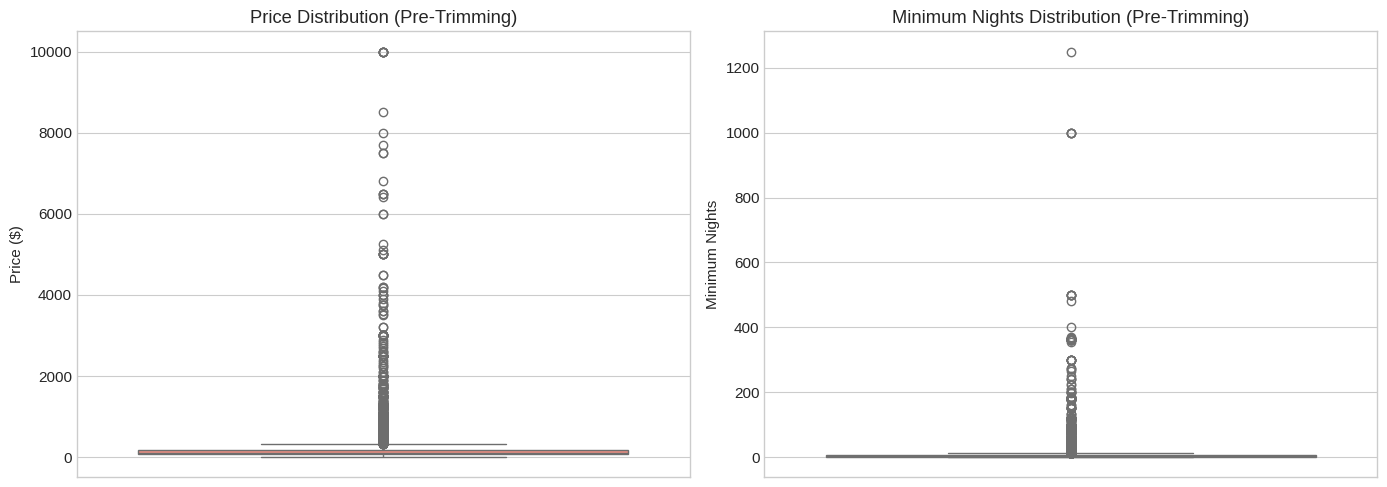

In [8]:
# ==============================================================================
# STEP 3: OUTLIER IDENTIFICATION & TREATMENT
# ==============================================================================
print("\n--- STEP 3: OUTLIER IDENTIFICATION & TREATMENT ---")

# Task 3.1: Visualizing distribution prior to trimming
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(y=df_cleaned['price'], ax=axes[0], color='salmon')
axes[0].set_title('Price Distribution (Pre-Trimming)')
axes[0].set_ylabel('Price ($)')

sns.boxplot(y=df_cleaned['minimum_nights'], ax=axes[1], color='skyblue')
axes[1].set_title('Minimum Nights Distribution (Pre-Trimming)')
axes[1].set_ylabel('Minimum Nights')
plt.tight_layout()
plt.show()

In [9]:
# Task 3.2: 95th Percentile Trimming
price_cap = df_cleaned['price'].quantile(0.95)
min_nights_cap = df_cleaned['minimum_nights'].quantile(0.95)

print(f"95th Percentile Threshold - Price: ${price_cap:.2f}")
print(f"95th Percentile Threshold - Minimum Nights: {min_nights_cap:.1f} nights")

initial_rows = len(df_cleaned)
df_trimmed = df_cleaned[
    (df_cleaned['price'] <= price_cap) &
    (df_cleaned['minimum_nights'] <= min_nights_cap)
].copy()
final_rows = len(df_trimmed)
print(f"Trimmed {initial_rows - final_rows} extreme outlier rows ({(initial_rows - final_rows)/initial_rows * 100:.2f}% of data)")

95th Percentile Threshold - Price: $355.00
95th Percentile Threshold - Minimum Nights: 30.0 nights
Trimmed 3136 extreme outlier rows (6.42% of data)


In [11]:
# ==============================================================================
# STEP 4: FEATURE SELECTION & CATEGORICAL ENCODING
# ==============================================================================
print("\n--- STEP 4: FEATURE SELECTION & CATEGORICAL ENCODING ---")

# Task 4.1: Drop high-cardinality neighbourhood column to avoid Curse of Dimensionality
df_trimmed.drop(columns=['neighbourhood'], inplace=True)
print("Dropped 'neighbourhood' column (high cardinality: 200+ unique categories).")




--- STEP 4: FEATURE SELECTION & CATEGORICAL ENCODING ---
Dropped 'neighbourhood' column (high cardinality: 200+ unique categories).


In [16]:
# STEP 5: FEATURE-TARGET SEPARATION & VALIDATION SPLIT
# ==============================================================================
print("\n--- STEP 5: TRAIN-TEST SPLIT ---")

# Task 5.1: X/y separation
X = df_encoded.drop(columns=['price'])
y = df_encoded['price']

# Task 5.2: 80/20 train-test split with fixed random seed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training Features Set: {X_train.shape}")
print(f"Testing Features Set:  {X_test.shape}")


--- STEP 5: TRAIN-TEST SPLIT ---
Training Features Set: (36598, 13)
Testing Features Set:  (9150, 13)


In [17]:
# STEP 6: MODEL TRAINING & EVALUATION
# ==============================================================================
print("\n--- STEP 6: MODEL TRAINING & METRICS ---")

# Task 6.1: Initialize and train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Task 6.2: Predict on testing data
y_pred = lr_model.predict(X_test)

# Task 6.3: Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R-Squared (R²) Score : {r2:.4f}")
print(f"Mean Absolute Error   : ${mae:.2f}")
print(f"Mean Squared Error    : {mse:.2f}")
print(f"Root Mean Squared Err : ${rmse:.2f}")

# Display feature weights
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient ($)': lr_model.coef_
}).sort_values(by='Coefficient ($)', ascending=False)
print("\nModel Coefficients:")
print(coefficients.to_string(index=False))


--- STEP 6: MODEL TRAINING & METRICS ---
R-Squared (R²) Score : 0.4868
Mean Absolute Error   : $38.32
Mean Squared Error    : 2760.62
Root Mean Squared Err : $52.54

Model Coefficients:
                          Feature  Coefficient ($)
    neighbourhood_group_Manhattan        23.448423
       neighbourhood_group_Queens         5.668208
   calculated_host_listings_count         0.136624
                 availability_365         0.074541
                number_of_reviews        -0.067895
                   minimum_nights        -1.038378
                reviews_per_month        -1.059533
     neighbourhood_group_Brooklyn        -8.210673
                         latitude       -76.227036
           room_type_Private room       -79.116921
neighbourhood_group_Staten Island       -82.933755
            room_type_Shared room      -104.577119
                        longitude      -297.507208


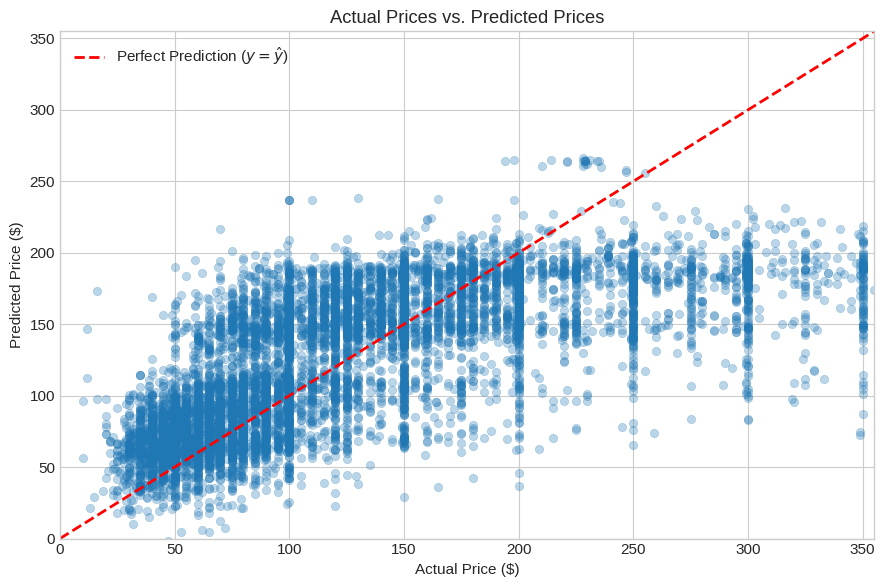

In [18]:
# STEP 7: RESIDUAL ANALYSIS & VISUALIZATION
# ==============================================================================
residuals = y_test - y_pred

# Task 7.1: Actual vs. Predicted Prices Plot
plt.figure(figsize=(9, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.3, color='#1f77b4', edgecolor=None)
# 45-degree perfect prediction reference line
max_val = max(y_test.max(), y_pred.max())
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction ($y = \\hat{y}$)')
plt.title('Actual Prices vs. Predicted Prices')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.xlim(0, max_val)
plt.ylim(0, max_val)
plt.legend()
plt.tight_layout()
plt.show()

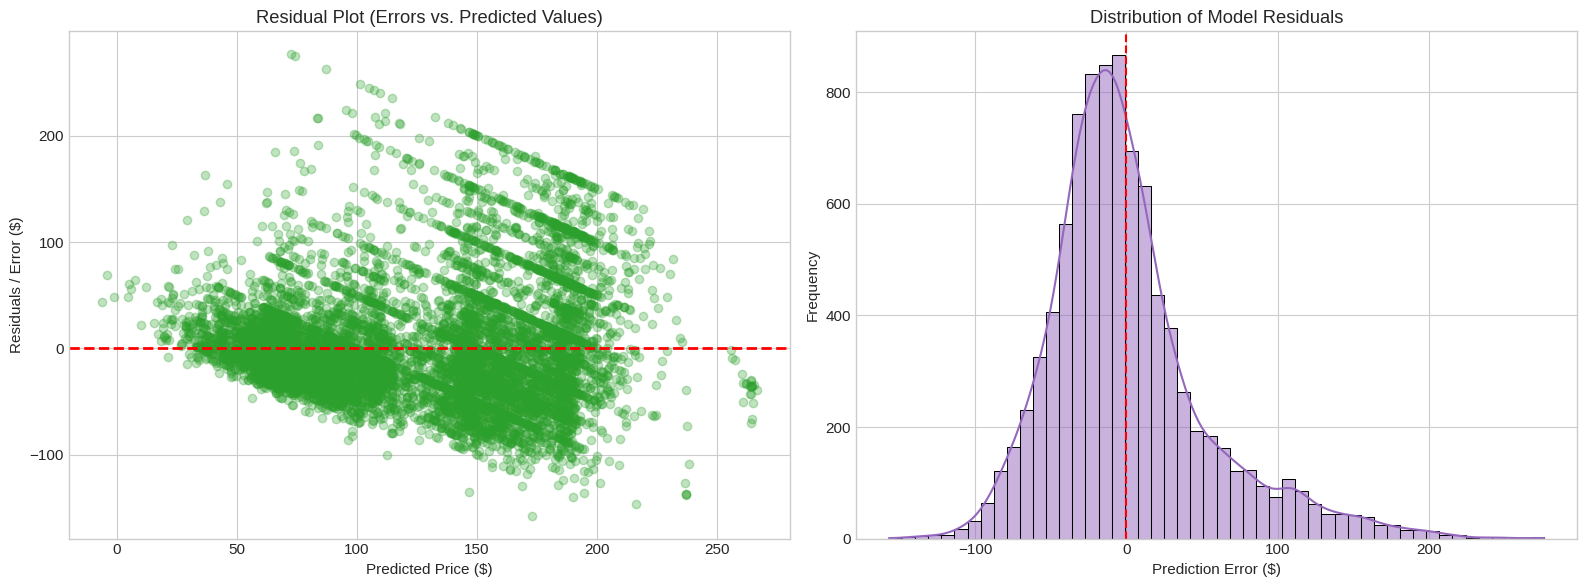

In [19]:
# Task 7.2: Residual Plot & Residual Distribution Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Residuals vs Fitted values
axes[0].scatter(y_pred, residuals, alpha=0.3, color='#2ca02c', edgecolor=None)
axes[0].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Residual Plot (Errors vs. Predicted Values)')
axes[0].set_xlabel('Predicted Price ($)')
axes[0].set_ylabel('Residuals / Error ($)')

# Error Distribution Histogram
sns.histplot(residuals, bins=50, kde=True, ax=axes[1], color='#9467bd')
axes[1].axvline(x=0, color='red', linestyle='--', linewidth=1.5)
axes[1].set_title('Distribution of Model Residuals')
axes[1].set_xlabel('Prediction Error ($)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()